In [88]:
#!pip install pyDOE
#!pip install tensorflow
#!pip install pydot
#!pip install graphviz

In [89]:
import tensorflow as tf
import numpy as np
from pyDOE import lhs
import matplotlib.pyplot as plt
import pydot
import graphviz
import math
import time

In [90]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
tf.config.list_physical_devices('GPU')
from tensorflow.python.client import device_lib
print(device_lib.list_local_devices())

Num GPUs Available:  0
[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 1361361164961653417
xla_global_id: -1
]


In [91]:
tf.keras.backend.set_floatx('float64')

In [92]:
# Boundaries of the computational domain
t0, tfinal = 0.0, 1
x0, xfinal = 0.0, 10

nu = 10

N_t = 20
N_x = 100

In [93]:
# Initial condition

def initial_cond(x) :
    
    return np.sin((2*np.pi*x)/xfinal)

In [94]:
with open('Burgers 10 0 1 0.001 0 10 0.001.npy', 'rb') as f:

    u_sol = np.load(f)
    
print(u_sol.shape)

(1001, 10001)


In [95]:
decimal_p = 4

In [96]:
# Define the normalization layer
class Normalize(tf.keras.layers.Layer):
  def __init__(self, xmin, xmax, name=None, **kwargs):
    super(Normalize, self).__init__(name=name)
    self.xmin = xmin
    self.xmax = xmax
    super(Normalize, self).__init__(**kwargs)

  def call(self, inputs):
    return 2.0*(inputs-self.xmin)/(self.xmax-self.xmin)-1.0

  def get_config(self):
    config = super(Normalize, self).get_config()
    config.update({'xmin': self.xmin, 'xmax': self.xmax})
    return config

In [97]:
# Define the network
def build_model(nr_units=40, nr_layers=4, summary=False):

    inpt = tf.keras.layers.Input(shape=(1,))
    inpx = tf.keras.layers.Input(shape=(1,))

    normt = Normalize(t0, tfinal)(inpt)
    normx = Normalize(x0, xfinal)(inpx)
        
    b = tf.keras.layers.Concatenate()([normt, normx])

    for i in range(nr_layers):
        b = tf.keras.layers.Dense(nr_units, activation='tanh')(b)
        
    out = tf.keras.layers.Dense(1, activation='linear')(b)
    #model = tf.keras.Sequential([Dense(10,activation='sigmoid')
    #out = tf.keras.layers.Dense(1, activation='sigmoid')(b)

    model = tf.keras.models.Model([inpx, inpt], out)
  
    if summary:
        model.summary()

    return model

In [98]:
model = build_model(summary = True)

Model: "model_6"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_13 (InputLayer)          [(None, 1)]          0           []                               
                                                                                                  
 input_14 (InputLayer)          [(None, 1)]          0           []                               
                                                                                                  
 normalize_25 (Normalize)       (None, 1)            0           ['input_13[0][0]']               
                                                                                                  
 normalize_27 (Normalize)       (None, 1)            0           ['input_14[0][0]']               
                                                                                            

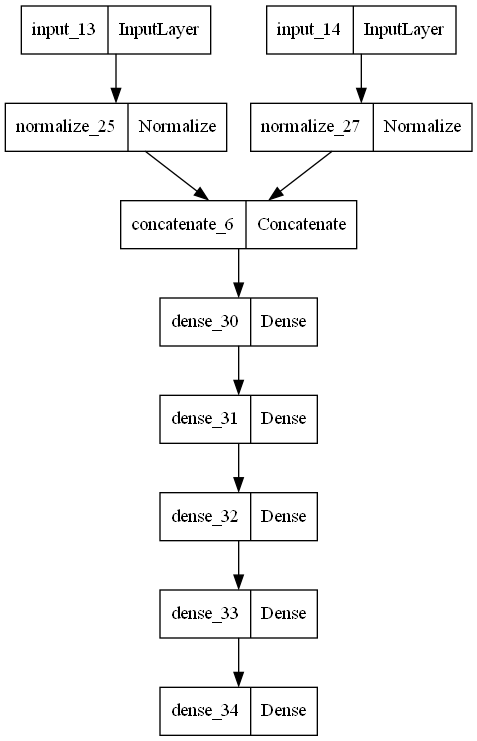

In [99]:
tf.keras.utils.plot_model(model)

In [1]:
def defineCollocationPoints(bdry, N):

    # Sample points where to evaluate the PDE
    points = bdry[0] + (bdry[1] - bdry[0])*lhs(1, N)

    return points

In [2]:
t0_arr = np.array([0.0])

NameError: name 'np' is not defined

In [3]:
# Define the collocation points
t_points = defineCollocationPoints([t0, tfinal], N_t - 1)
t_points = np.vstack((t0_arr, t_points))

x_points = defineCollocationPoints([x0, xfinal], N_x)

u_init = initial_cond(x_points)

tv, xv = np.meshgrid(t_points, x_points)

tv_flat = tv.flatten()
xv_flat = xv.flatten()

t_points_flat = np.reshape(tv_flat, (tv_flat.size, 1))
x_points_flat = np.reshape(xv_flat, (xv_flat.size, 1))

tx_points_flat = np.hstack((t_points_flat, x_points_flat))

print(t_points_flat.shape)
print(x_points_flat.shape)
print(tx_points_flat.shape)

NameError: name 't0' is not defined

In [103]:
# Define the initial points

t_initial = np.zeros((N_x, 1))
x_initial = x_points
u_initial =initial_cond(x_initial)

t_inits = tf.convert_to_tensor(t_initial, dtype = tf.float64)
x_inits = tf.convert_to_tensor(x_initial, dtype = tf.float64)
u_inits = tf.convert_to_tensor(u_initial, dtype = tf.float64)


print(t_inits.shape)
print(x_inits.shape)
print(u_inits.shape)

(100, 1)
(100, 1)
(100, 1)


In [104]:
t_boundary_0 = t_points
x_boundary_0 = np.full((len(t_boundary_0), 1), x0, dtype = np.float64)

t_boundary_1 = t_points
x_boundary_1 = np.full((len(t_boundary_1), 1), xfinal, dtype = np.float64)

t_boundaries = np.vstack((t_boundary_0, t_boundary_1))
x_boundaries = np.vstack((x_boundary_0, x_boundary_1))


print(t_boundaries.shape)
print(x_boundaries.shape)

(40, 1)
(40, 1)


Text(0.5, 1.0, 'Collocation points being used')

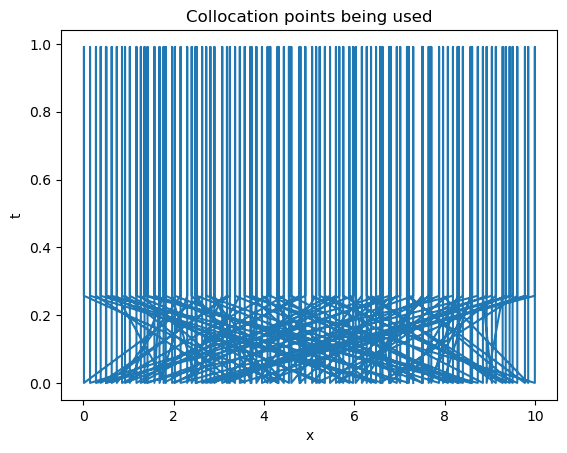

In [105]:
plt.plot(x_points_flat, t_points_flat)
plt.xlabel('x')
plt.ylabel('t')

plt.title('Collocation points being used')

In [106]:
def image_plot(tmin, tmax, xmin, xmax, u, title) :

    plt.figure()
    plt.xlabel("x")
    plt.ylabel("t")
    plt.imshow(np.flipud(u), aspect = 8, interpolation = 'none', extent = [xmin, xmax, tmin, tmax])
    plt.set_cmap('coolwarm')
    plt.title(title)
    plt.colorbar()
    plt.show()

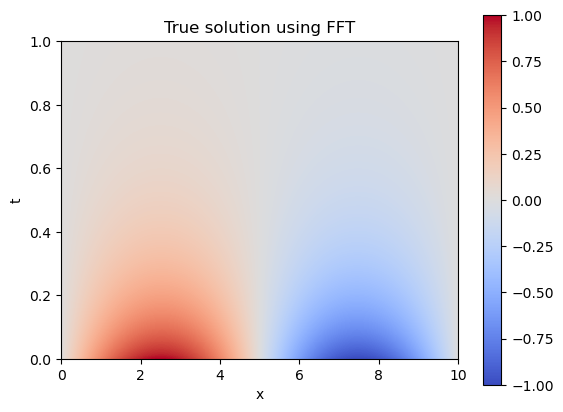

In [107]:
image_plot(t0, tfinal, x0, xfinal, u_sol, "True solution using FFT")

In [108]:
# The main training function
@tf.function
def train_network(pdes, inits, model, alpha, beta, gamma):

    # DE collocation points
    t_de = pdes[:, :1]
    x_de = pdes[:, 1:]
    
    t_de = tf.convert_to_tensor(t_points_flat, dtype = tf.float64)
    x_de = tf.convert_to_tensor(x_points_flat, dtype = tf.float64)
    
    t_b = tf.convert_to_tensor(t_boundaries, dtype = tf.float64)
    x_b = tf.convert_to_tensor(x_boundaries, dtype = tf.float64)
    
    # Initial value points
    #t_init, x_init, u_init = tf.reshape(inits[0], (1, )), tf.reshape(inits[1], (1, )), tf.reshape(inits[2], (1, ))
    
    t_init = t_inits
    x_init = x_inits
    u_init = u_inits
    

    with tf.GradientTape() as tape:
        
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch(x_de)
            
            with tf.GradientTape(persistent=True) as tape2:
                tape2.watch(x_de)
                
                
                with tf.GradientTape(persistent=True) as tape3:
                    tape3.watch(t_de)

                    u = model([t_de, x_de], training=True)

                ut = tape3.gradient(u, t_de)

            ux = tape2.gradient(u, x_de)
        
        uxx = tape1.gradient(ux, x_de)

        
        # Define the differential equation loss
        eqn = ut + (u * ux) - (nu * uxx)

        DEloss = tf.reduce_mean(tf.square(eqn))
                         
        # Define the initial value loss
        u_init_pred = model([t_init, x_init], training=True)
        
        IVloss = tf.reduce_mean(tf.square(u_init_pred - u_init))
    
        u_boundaries_pred = model([t_b, x_b], training=True)
        Bloss = tf.reduce_mean(tf.square(u_boundaries_pred))
        
        # Composite loss function
        loss = alpha*DEloss + beta*IVloss + gamma*Bloss

    grads = tape.gradient(loss, model.trainable_variables)
    
    return DEloss, IVloss, Bloss, grads

In [109]:
def train_plot(epochs, alpha, beta, gamma) :
    
    loss, model = PINNtrain(epochs, alpha, beta, gamma)
    
    # Grid where to evaluate the model
    t_step_size = 0.001
    x_step_size = 0.001
    
    n_t = int(((tfinal - t0)/t_step_size) + 1)
    n_x = int(((xfinal - x0)/x_step_size) + 1)
    
    t = np.linspace(t0, tfinal, n_t)
    x = np.linspace(x0, xfinal, n_x)
    
    num_t = t.shape[0]
    num_x = x.shape[0]

    t, x = np.meshgrid(t, x)

    t = t.flatten()
    x = x.flatten()

    t = np.reshape(t, (t.size, 1))
    x = np.reshape(x, (x.size, 1))
    
    plt.figure(1)
    plt.semilogy(loss)
    plt.xlabel("epoch")
    plt.ylabel("loss")

    # Model prediction
    u = model([t, x])

    u = tf.transpose(tf.reshape(u, [num_x, num_t]))
                   
    print(u.shape)
    print(u_sol.shape)
    
    image_plot(t0, tfinal, x0, xfinal, u_sol, "True solution using FFT")
    image_plot(t0, tfinal, x0, xfinal, u, "Predicted Solution")
    image_plot(t0, tfinal, x0, xfinal, u - u_sol, "Difference between FFT and Predicted Solutions")
    
    # Plot the solution
#     print(len(x))
    
#     plt.figure(2)
#     plt.plot(x, y, label = "e = " + str(epochs) + ", gamma = " + str(gamma) + ", epsilon = " + str(epsilon))
#     plt.legend(loc='best')
#     plt.plot(xpoints, ypoints, color = 'black')
    
#     error = calc_err(t, x, y)    
    
#     plt.figure(3)
#     print(epsilon, error)
#     plt.scatter(epsilon, error)
    


In [110]:
def calc_err(t_preds, x_preds, y_preds) :
    
    error = 0
    
    for i in range(len(t_preds)) :
        
        t_i = np.where(tpoints == t_preds[i])
        
        err = np.abs(x_preds[i] - xpoints[t_i])  + np.abs(y_preds[i] - ypoints[t_i])
        
        error = error + err
        
    return error

In [111]:
def PINNtrain(epochs, alpha_val, beta_val, gamma_val):
    
    t_points = t_points_flat
    x_points = x_points_flat
    tx_points = tx_points_flat
    
    N_total = len(t_points)
    
    N_batch = N_total//100

    alpha = alpha_val
    beta = beta_val
    gamma = gamma_val

    # Learning rate
    lr_model = 1e-3

    # Initial value
    t_init = t_initial
    x_init = x_initial
    u_init = u_initial

    epoch_loss = np.zeros(epochs)
    nr_batches = 0

    # Generate the tf.Dataset for the initial collocation points
    inits = np.column_stack([t_init, x_init, u_init])
    ds_init = tf.data.Dataset.from_tensor_slices(inits)
    ds_init = ds_init.cache()


    # Generate the tf.Dataset for the differential equations points
    ds_pde = tf.data.Dataset.from_tensor_slices(tx_points.astype(np.float32))
    ds_pde = ds_pde.cache().shuffle(N_total).batch(N_batch)

    # Generate entire dataset
    ds = tf.data.Dataset.zip((ds_pde, ds_init))

    ds = ds.prefetch(tf.data.experimental.AUTOTUNE)

    
    # Generate the model
    opt = tf.keras.optimizers.Adam(lr_model)
    model = build_model() 

    # Main training loop
    for i in range(epochs):
        
        print("epoch no", i)

        # Training for that epoch
        for (des, inits) in ds:
            
            # Train the network
            DEloss, IVloss, Bloss, grads = train_network(des, inits, model, alpha, beta, gamma)

            # Gradient step
            opt.apply_gradients(zip(grads, model.trainable_variables))
      
            epoch_loss[i] += alpha*DEloss + beta*IVloss + gamma*Bloss
            nr_batches = nr_batches + 1

        # Get total epoch loss
        epoch_loss[i] = epoch_loss[i]/nr_batches
        nr_batches = 0
    
    
        if (np.mod(i, 5)==0):
            print("DE loss, IV loss, Bloss in {}th epoch: {: 6.7f}, {: 6.7f}, {: 6.7f}.".format(i, DEloss, IVloss, Bloss))

    return epoch_loss, model

In [112]:
start = time.time()

epoch no 0
DE loss, IV loss, Bloss in 0th epoch:  0.0151291,  0.3252901,  0.0569821.
epoch no 1
epoch no 2
epoch no 3
epoch no 4
epoch no 5
DE loss, IV loss, Bloss in 5th epoch:  0.0424385,  0.1424960,  0.0481542.
epoch no 6
epoch no 7
epoch no 8
epoch no 9
epoch no 10
DE loss, IV loss, Bloss in 10th epoch:  0.0355793,  0.1221190,  0.0591256.
epoch no 11
epoch no 12
epoch no 13
epoch no 14
epoch no 15
DE loss, IV loss, Bloss in 15th epoch:  0.0353575,  0.1165702,  0.0590654.
epoch no 16
epoch no 17
epoch no 18
epoch no 19
epoch no 20
DE loss, IV loss, Bloss in 20th epoch:  0.0371055,  0.1107067,  0.0582136.
epoch no 21
epoch no 22
epoch no 23
epoch no 24
epoch no 25
DE loss, IV loss, Bloss in 25th epoch:  0.0341639,  0.1175991,  0.0541253.
epoch no 26
epoch no 27
epoch no 28
epoch no 29
epoch no 30
DE loss, IV loss, Bloss in 30th epoch:  0.0368372,  0.0987476,  0.0532890.
epoch no 31
epoch no 32
epoch no 33
epoch no 34
epoch no 35
DE loss, IV loss, Bloss in 35th epoch:  0.0252913,  0.0

DE loss, IV loss, Bloss in 295th epoch:  0.0004731,  0.0006216,  0.0000182.
epoch no 296
epoch no 297
epoch no 298
epoch no 299
epoch no 300
DE loss, IV loss, Bloss in 300th epoch:  0.0002437,  0.0003035,  0.0000215.
epoch no 301
epoch no 302
epoch no 303
epoch no 304
epoch no 305
DE loss, IV loss, Bloss in 305th epoch:  0.0011685,  0.0008971,  0.0000176.
epoch no 306
epoch no 307
epoch no 308
epoch no 309
epoch no 310
DE loss, IV loss, Bloss in 310th epoch:  0.0002702,  0.0002283,  0.0000123.
epoch no 311
epoch no 312
epoch no 313
epoch no 314
epoch no 315
DE loss, IV loss, Bloss in 315th epoch:  0.0007605,  0.0007693,  0.0000104.
epoch no 316
epoch no 317
epoch no 318
epoch no 319
epoch no 320
DE loss, IV loss, Bloss in 320th epoch:  0.0001814,  0.0002427,  0.0000106.
epoch no 321
epoch no 322
epoch no 323
epoch no 324
epoch no 325
DE loss, IV loss, Bloss in 325th epoch:  0.0001186,  0.0001145,  0.0000074.
epoch no 326
epoch no 327
epoch no 328
epoch no 329
epoch no 330
DE loss, IV l

epoch no 587
epoch no 588
epoch no 589
epoch no 590
DE loss, IV loss, Bloss in 590th epoch:  0.0003280,  0.0004867,  0.0000061.
epoch no 591
epoch no 592
epoch no 593
epoch no 594
epoch no 595
DE loss, IV loss, Bloss in 595th epoch:  0.0000118,  0.0000070,  0.0000030.
epoch no 596
epoch no 597
epoch no 598
epoch no 599
epoch no 600
DE loss, IV loss, Bloss in 600th epoch:  0.0000231,  0.0000161,  0.0000036.
epoch no 601
epoch no 602
epoch no 603
epoch no 604
epoch no 605
DE loss, IV loss, Bloss in 605th epoch:  0.0005325,  0.0007318,  0.0000045.
epoch no 606
epoch no 607
epoch no 608
epoch no 609
epoch no 610
DE loss, IV loss, Bloss in 610th epoch:  0.0007281,  0.0010841,  0.0000125.
epoch no 611
epoch no 612
epoch no 613
epoch no 614
epoch no 615
DE loss, IV loss, Bloss in 615th epoch:  0.0000974,  0.0000084,  0.0000066.
epoch no 616
epoch no 617
epoch no 618
epoch no 619
epoch no 620
DE loss, IV loss, Bloss in 620th epoch:  0.0001611,  0.0001663,  0.0000186.
epoch no 621
epoch no 622


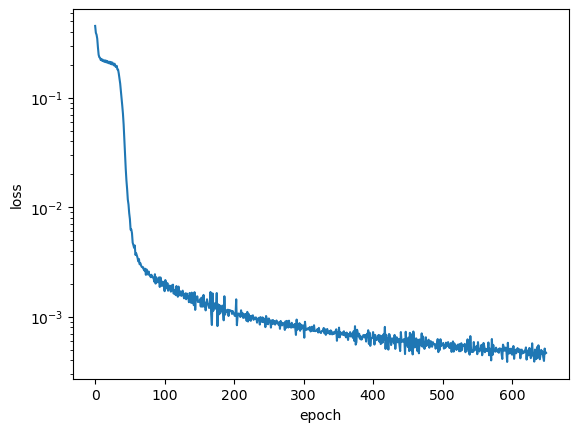

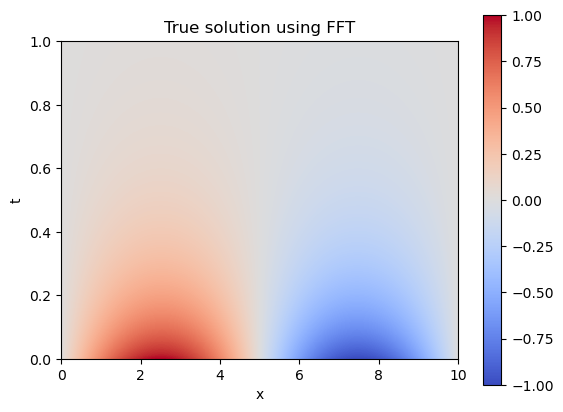

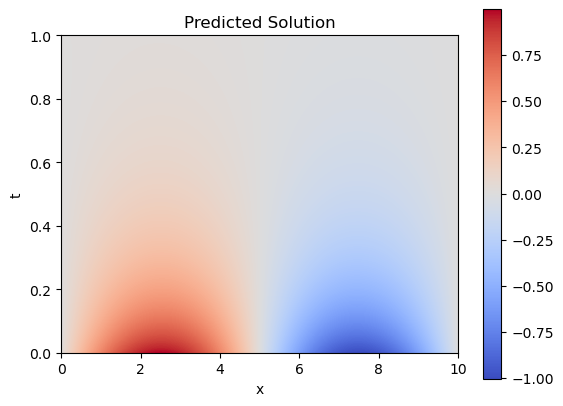

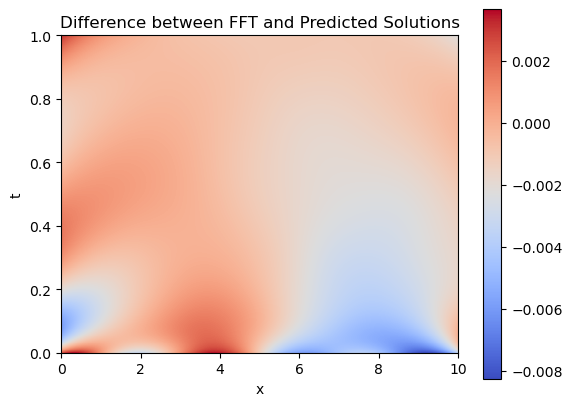

In [113]:
train_plot(650, 1, 1, 1)

In [114]:
end = time.time()

print((end-start)/60)

31.160935640335083
